# Predicting Movie Profitability
**Oliver Flynn**

Exploring a dataset of ~3,900 films and building classification models (Decision Tree, Logistic Regression, Random Forest) to predict whether a film is profitable (box office > budget).

**Data:** [Movies (IMDb, Earnings and more)](https://www.kaggle.com/datasets/delfinaoliva/movies) by Delfina Oliva on Kaggle. The data is not included in this repo. Download it and save the cleaned version as `movies_data_new.csv` in the same folder as this notebook to run it.


## Part 1: Data Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('movies_data_new.csv')
print(df.shape)

(3905, 13)


In [ ]:
df.head()

,Movie,Director,Running time,Genre,Budget,Box Office,Director Box Office %,Earnings,Oscar and Golden Globes nominations,Oscar and Golden Globes awards,Release year,IMDb score,Profitable
0,13 Hours,Michael Bay,144,Action,50000000,69400000,69.23,19400000,0,0,2016,7.4,True
1,16 Blocks,Richard Donner,102,Action,52000000,65000000,50.00,13000000,0,0,2006,6.6,True
2,17 Again,Burr Steers,102,Comedy,20000000,139000000,25.00,119000000,0,0,2009,6.4,True
3,1982,Tommy Oliver,90,Drama,1000000,2000000,100.00,1000000,0,0,2013,7.1,True
4,2 Fast 2 Furious,John Singleton,107,Action,76000000,236000000,42.85,160000000,0,0,2003,5.9,True


In [3]:
df.tail()

,Movie,Director,Running time,Genre,Budget,Box Office,Director Box Office %,Earnings,Oscar and Golden Globes nominations,Oscar and Golden Globes awards,Release year,IMDb score,Profitable
3900,Z Storm,David Lam,92,Action,7000000,17000000,100.00,10000000,0,0,2014,5.3,True
3901,Zack and Miri Make a Porno,Kevin Smith,101,Comedy,24000000,42000000,41.66,18000000,0,0,2008,6.6,True
3902,Zero Effect,Jake Kasdan,116,Comedy,5000000,2000000,50.00,-3000000,0,0,1998,7.0,False
3903,Zombieland,Ruben Fleischer,88,Adventure,23600000,102000000,33.33,78400000,0,0,2009,7.7,True
3904,Zulu,Jérôme Salle,110,Crime,16000000,5000000,0.00,-11000000,0,0,2013,6.7,False


In [4]:
df.isnull().sum()

Movie                                  0
Director                               0
Running time                           0
Genre                                  0
Budget                                 0
Box Office                             0
Director Box Office %                  0
Earnings                               0
Oscar and Golden Globes nominations    0
Oscar and Golden Globes awards         0
Release year                           0
IMDb score                             0
Profitable                             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.columns

Index(['Movie', 'Director', 'Running time', 'Genre', 'Budget', 'Box Office',
       'Director Box Office %', 'Earnings',
       'Oscar and Golden Globes nominations', 'Oscar and Golden Globes awards',
       'Release year', 'IMDb score', 'Profitable'],
      dtype='str')

In [7]:
df.Genre.value_counts(dropna=False)

Genre
Comedy         1002
Action          940
Drama           594
Crime           261
Adventure       235
Biography       230
Horror          218
Animation       177
Thriller        100
Sci-Fi           67
Documentary      46
Mystery          20
Western          11
Romance           4
Name: count, dtype: int64

/tmp/ipykernel_325/997838549.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Genre", data=df, palette="rocket", order=df.Genre.value_counts().index)


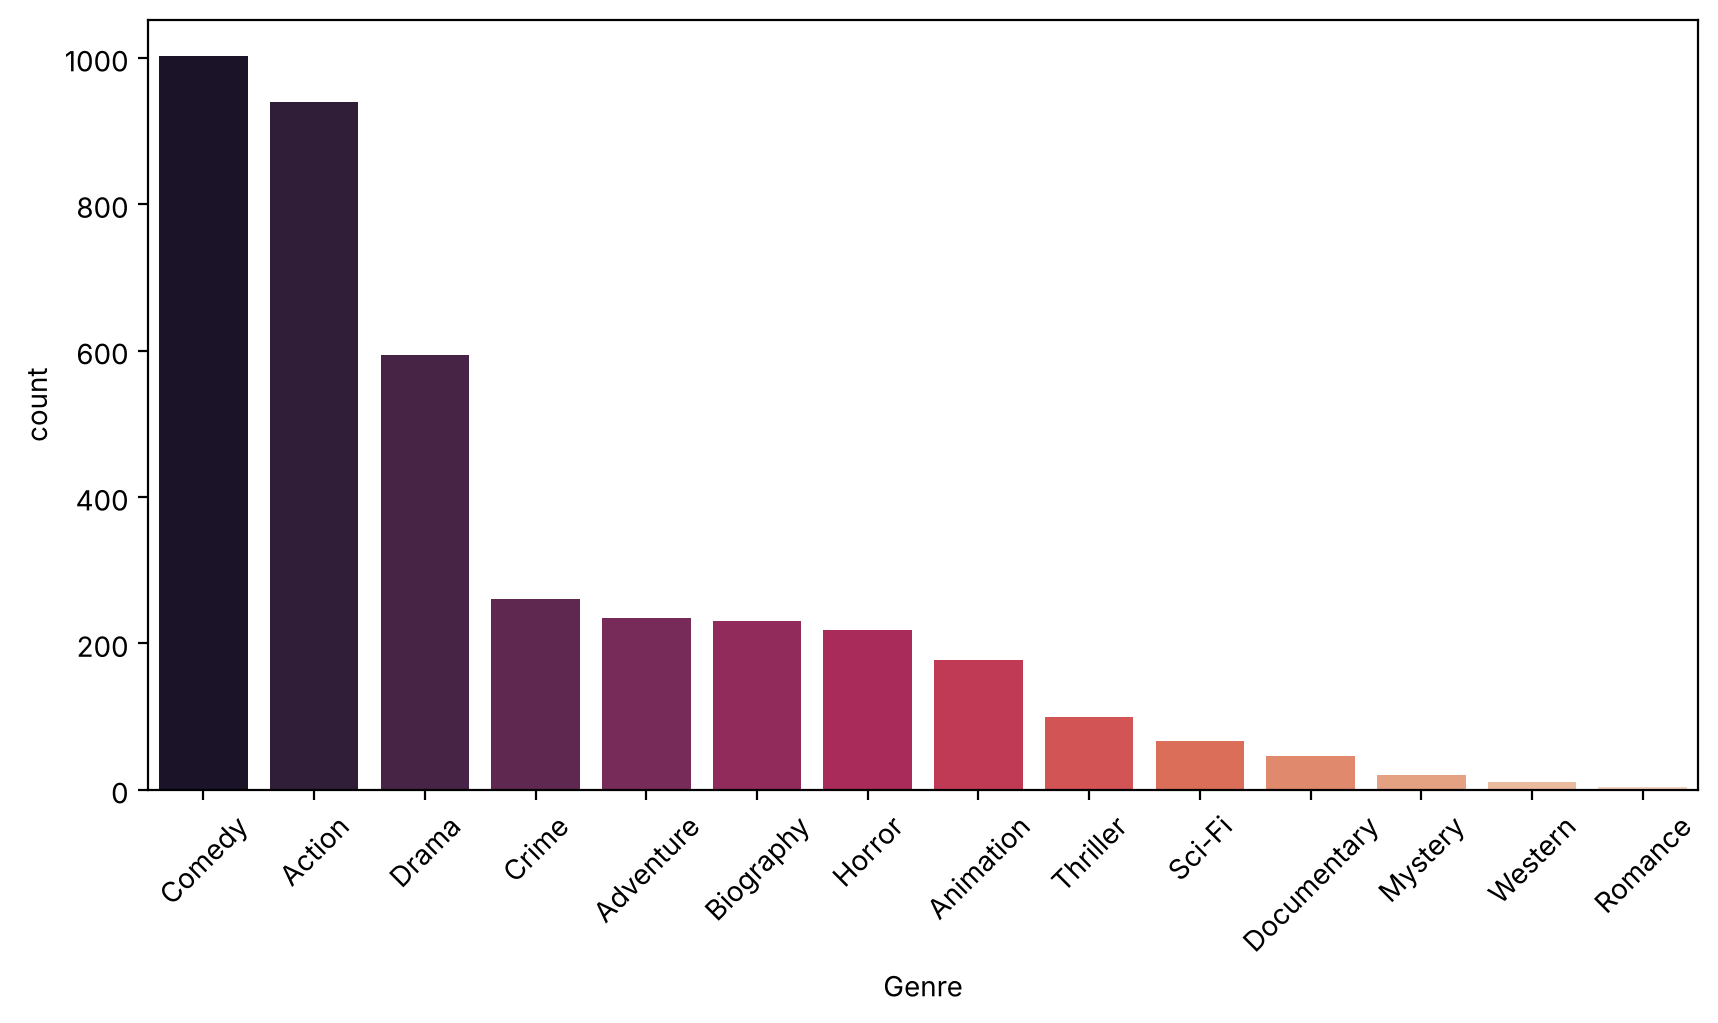

In [8]:
plt.figure(figsize=(10,5))
sns.countplot(x="Genre", data=df, palette="rocket", order=df.Genre.value_counts().index)
plt.xticks(rotation=45)
plt.show()

In [9]:
genre_percent = (df.Genre.value_counts(normalize=True) * 100).round(2)
print(genre_percent)

Genre
Comedy         25.66
Action         24.07
Drama          15.21
Crime           6.68
Adventure       6.02
Biography       5.89
Horror          5.58
Animation       4.53
Thriller        2.56
Sci-Fi          1.72
Documentary     1.18
Mystery         0.51
Western         0.28
Romance         0.10
Name: proportion, dtype: float64


In [10]:
df.Director.value_counts().head(10)

Director
Steven Spielberg     26
Woody Allen          21
Clint Eastwood       20
Martin Scorsese      18
Ridley Scott         16
Spike Lee            16
Renny Harlin         15
Steven Soderbergh    15
Oliver Stone         14
Robert Zemeckis      13
Name: count, dtype: int64

In [11]:
df.Director.nunique()

1760

In [12]:
df['Oscar and Golden Globes nominations'].value_counts(dropna=False).sort_index()

Oscar and Golden Globes nominations
0     2800
1      442
2      162
3       99
4       56
5       69
6       52
7       38
8       40
9       24
10      30
11      21
12      18
13      14
14      11
15       9
16       5
17       2
18       9
19       1
20       1
22       2
Name: count, dtype: int64

/tmp/ipykernel_325/1864467094.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Oscar and Golden Globes nominations", data=df, palette="rocket")


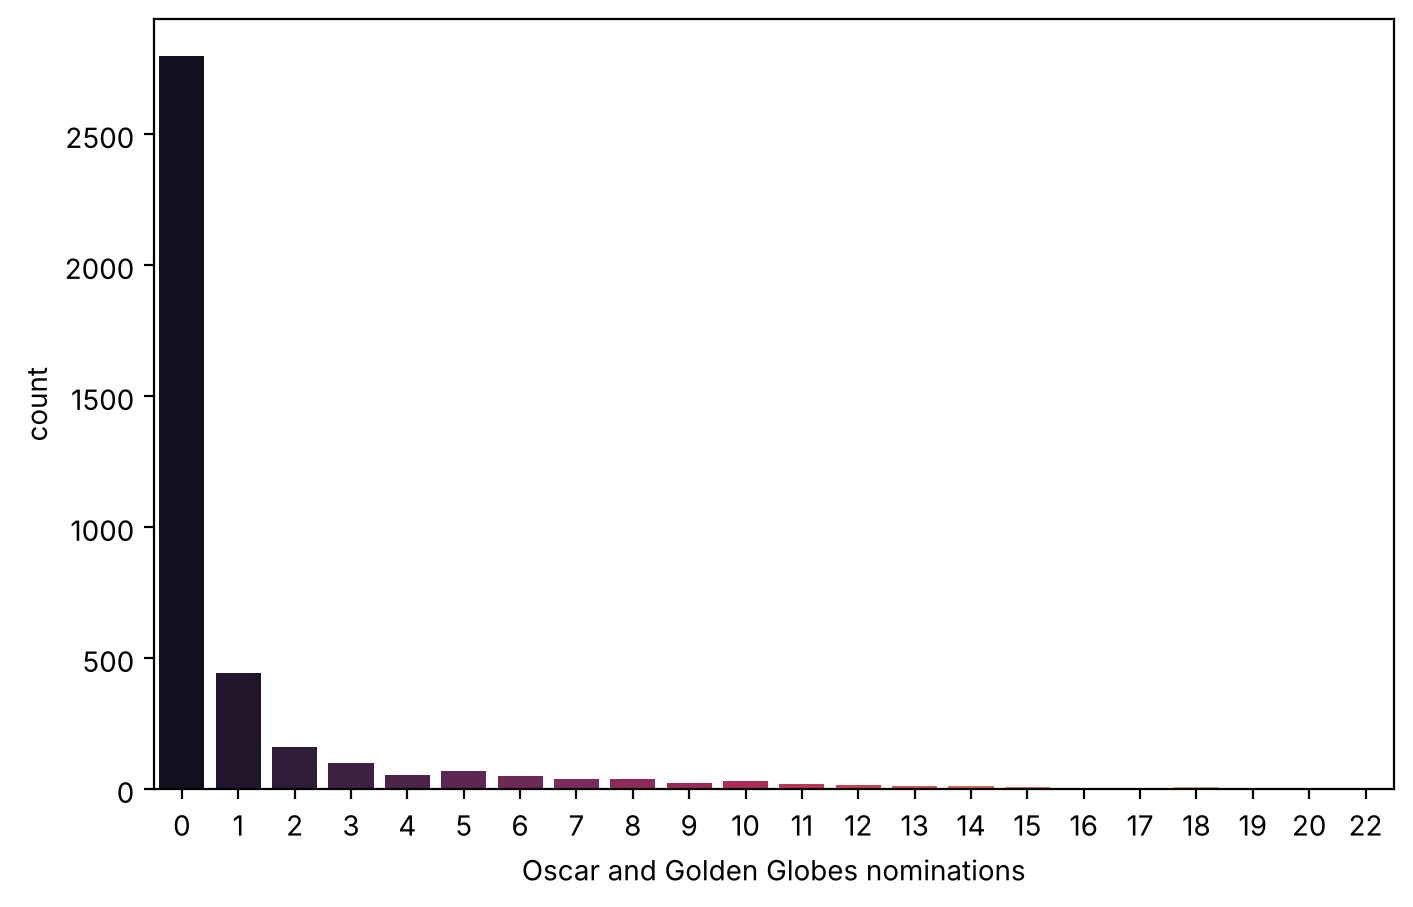

In [13]:
plt.figure(figsize=(8,5))
sns.countplot(x="Oscar and Golden Globes nominations", data=df, palette="rocket")
plt.show()

In [14]:
df['Oscar and Golden Globes awards'].value_counts(dropna=False).sort_index()

Oscar and Golden Globes awards
0     3450
1      202
2       88
3       38
4       41
5       29
6       17
7       14
8        8
9        7
10       2
11       3
12       2
13       4
Name: count, dtype: int64

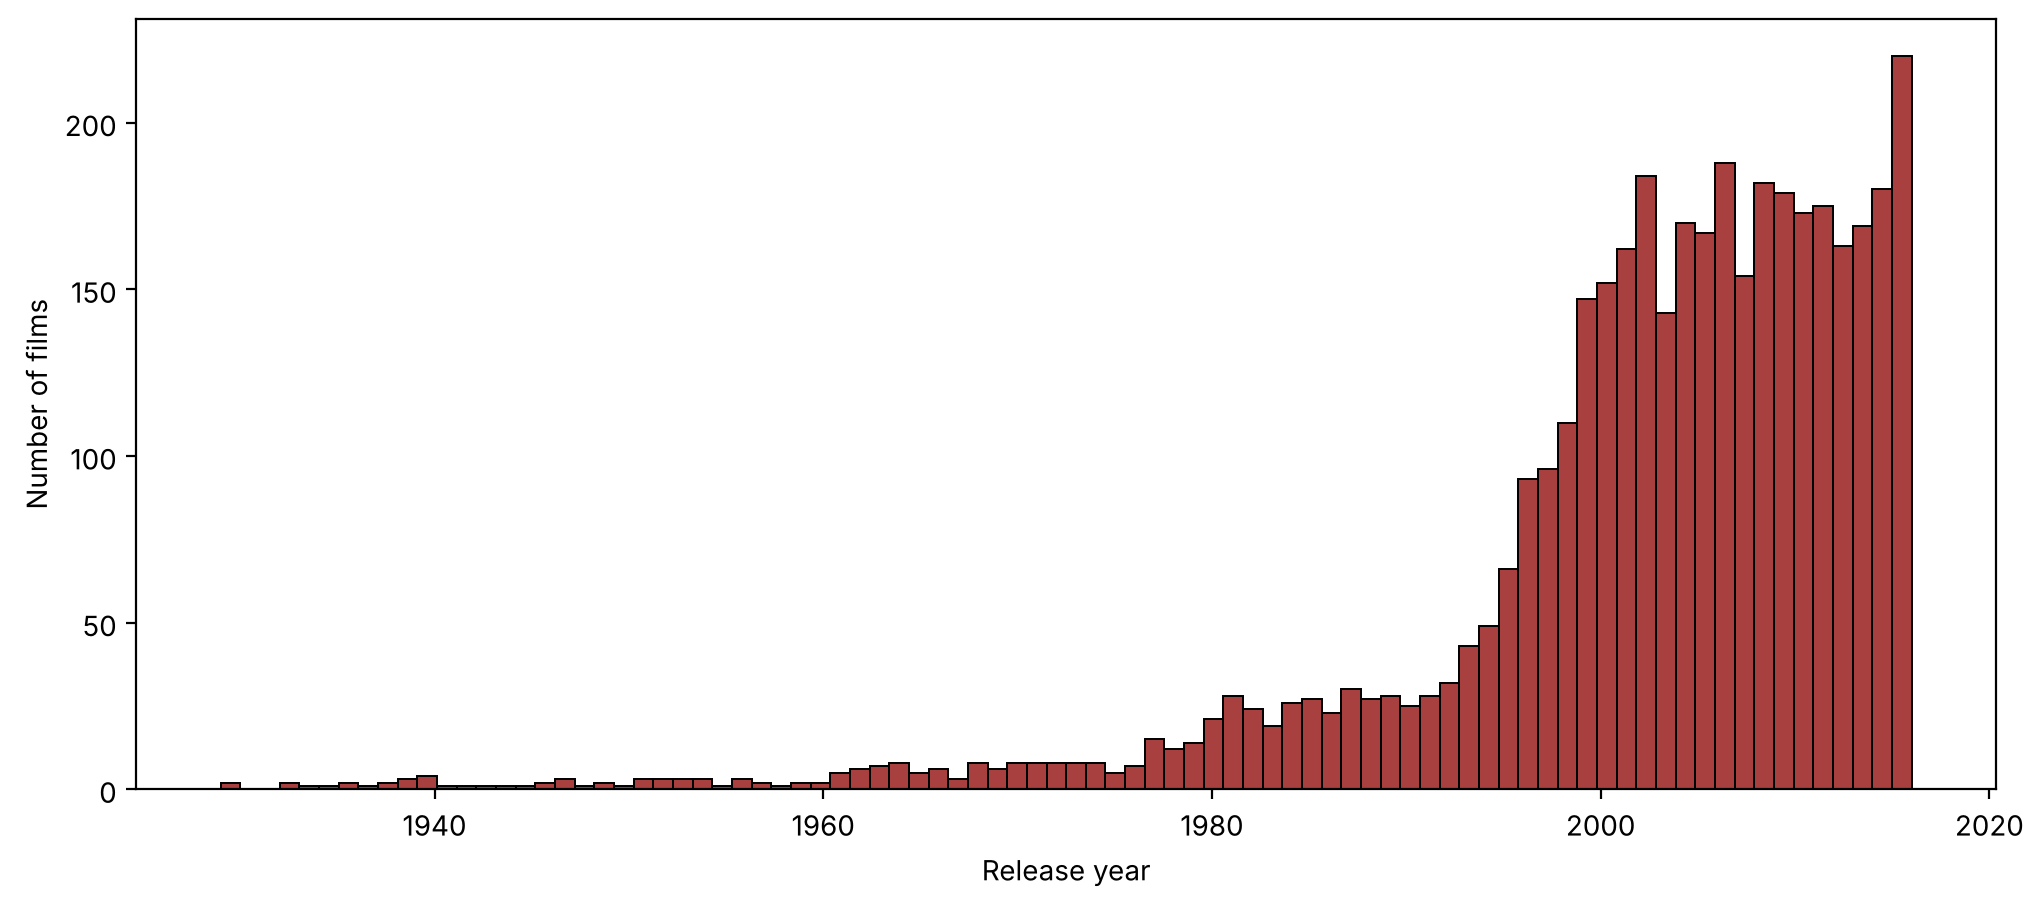

In [15]:
plt.figure(figsize=(12,5))
sns.histplot(df['Release year'], bins=df['Release year'].nunique(), color="darkred")
plt.xlabel("Release year")
plt.ylabel("Number of films")
plt.show()

In [16]:
df['Running time'].describe()

count    3905.000000
mean      109.930346
std        22.436825
min        45.000000
25%        95.000000
50%       105.000000
75%       120.000000
max       330.000000
Name: Running time, dtype: float64

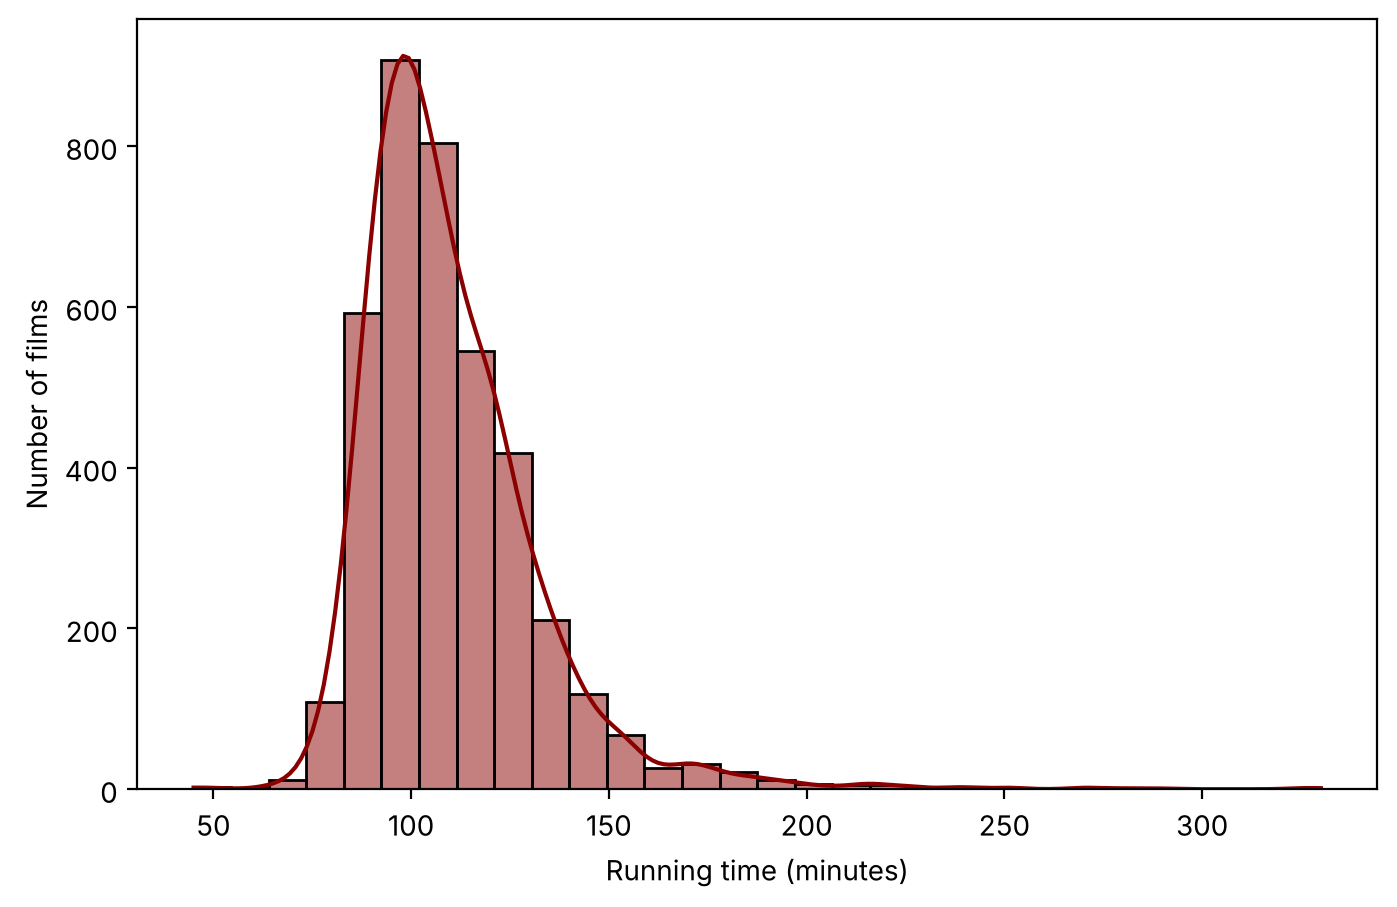

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df['Running time'], bins=30, color="darkred", kde=True)
plt.xlabel("Running time (minutes)")
plt.ylabel("Number of films")
plt.show()

In [18]:
df['IMDb score'].describe()

count    3905.000000
mean        6.466197
std         1.074108
min         1.600000
25%         5.900000
50%         6.600000
75%         7.200000
max         9.300000
Name: IMDb score, dtype: float64

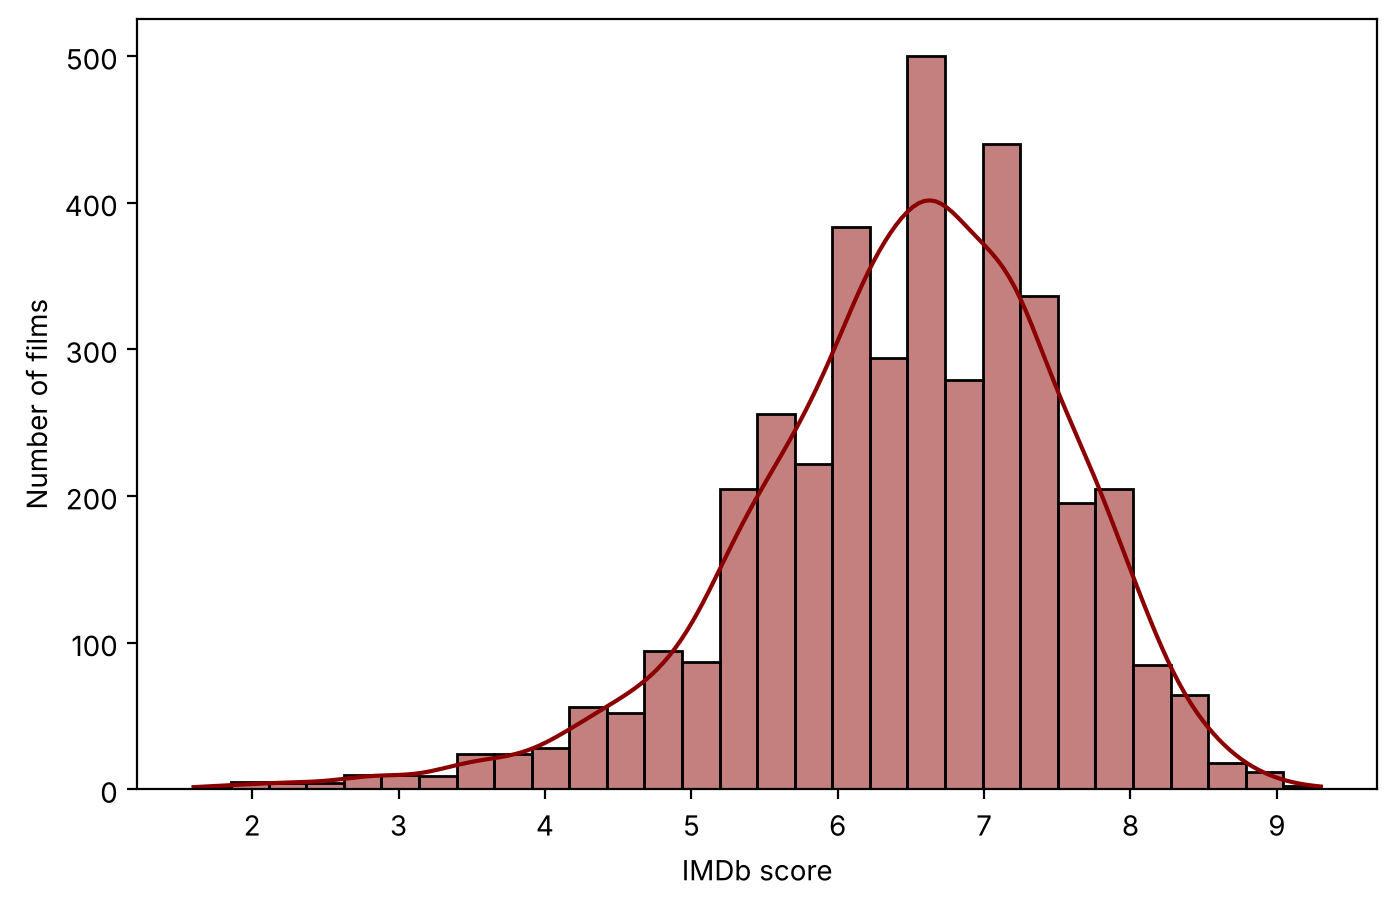

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df['IMDb score'], bins=30, color="darkred", kde=True)
plt.xlabel("IMDb score")
plt.ylabel("Number of films")
plt.show()

In [20]:
df['Budget_millions'] = df['Budget'] / 1_000_000
df['Budget_millions'].describe()

count    3905.000000
mean       36.101716
std        41.480174
min         0.001100
25%         8.700000
50%        22.000000
75%        49.000000
max       300.000000
Name: Budget_millions, dtype: float64

In [21]:
df['BoxOffice_millions'] = df['Box Office'] / 1_000_000
df['BoxOffice_millions'].describe()

count    3905.000000
mean      106.767596
std       177.989522
min         0.050000
25%        12.000000
50%        42.200000
75%       123.000000
max      2923.000000
Name: BoxOffice_millions, dtype: float64

In [22]:
df['Earnings_millions'] = df['Earnings'] / 1_000_000
df['Earnings_millions'].describe()

count    3905.000000
mean       70.665879
std       151.333629
min      -188.500000
25%        -0.095000
50%        18.000000
75%        79.000000
max      2686.000000
Name: Earnings_millions, dtype: float64

In [23]:
numeric_cols = ['Running time', 'Budget', 'Box Office', 'Director Box Office %',
                'Earnings', 'Oscar and Golden Globes nominations',
                'Oscar and Golden Globes awards', 'Release year', 'IMDb score']

z = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
df['dist_from_avg'] = np.sqrt((z**2).sum(axis=1))
df.sort_values('dist_from_avg').head(1)

,Movie,Director,Running time,Genre,Budget,Box Office,Director Box Office %,Earnings,Oscar and Golden Globes nominations,Oscar and Golden Globes awards,Release year,IMDb score,Profitable,Budget_millions,BoxOffice_millions,Earnings_millions,dist_from_avg
123,Behind Enemy Lines,John Moore,106,Action,40000000,91000000,50.0,51000000,0,0,2001,6.4,True,40.0,91.0,51.0,0.560175


In [24]:
df[numeric_cols].mean()

Running time                           1.099303e+02
Budget                                 3.610172e+07
Box Office                             1.067676e+08
Director Box Office %                  5.264150e+01
Earnings                               7.066588e+07
Oscar and Golden Globes nominations    1.107042e+00
Oscar and Golden Globes awards         3.218950e-01
Release year                           2.001979e+03
IMDb score                             6.466197e+00
dtype: float64

## Part 2: Pre-processing and Modelling

In [25]:
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('movies_data_new.csv')
print(df.shape)

(3905, 13)


In [26]:
df = df.drop(columns=['Movie'])

if 'Profitability' not in df.columns:
    df['Profitability'] = (df['Box Office'] > df['Budget']).astype(int)

df = df.drop(columns=['Box Office', 'Earnings', 'Profitable'])

df = pd.get_dummies(df, columns=['Genre'], drop_first=True)

director_counts = df['Director'].value_counts()
top10_directors = director_counts.head(10).index.tolist()

def bucket_director(name):
    if name in top10_directors:
        return name
    return f'{director_counts[name]} film(s) directed'

df['Director'] = df['Director'].apply(bucket_director)
df = pd.get_dummies(df, columns=['Director'], drop_first=True)

skewed_cols = ['Running time', 'Budget',
               'Oscar and Golden Globes nominations',
               'Oscar and Golden Globes awards']
for col in skewed_cols:
    df[col] = np.sqrt(df[col])

X = df.drop(columns=['Profitability'])
y = df['Profitability']

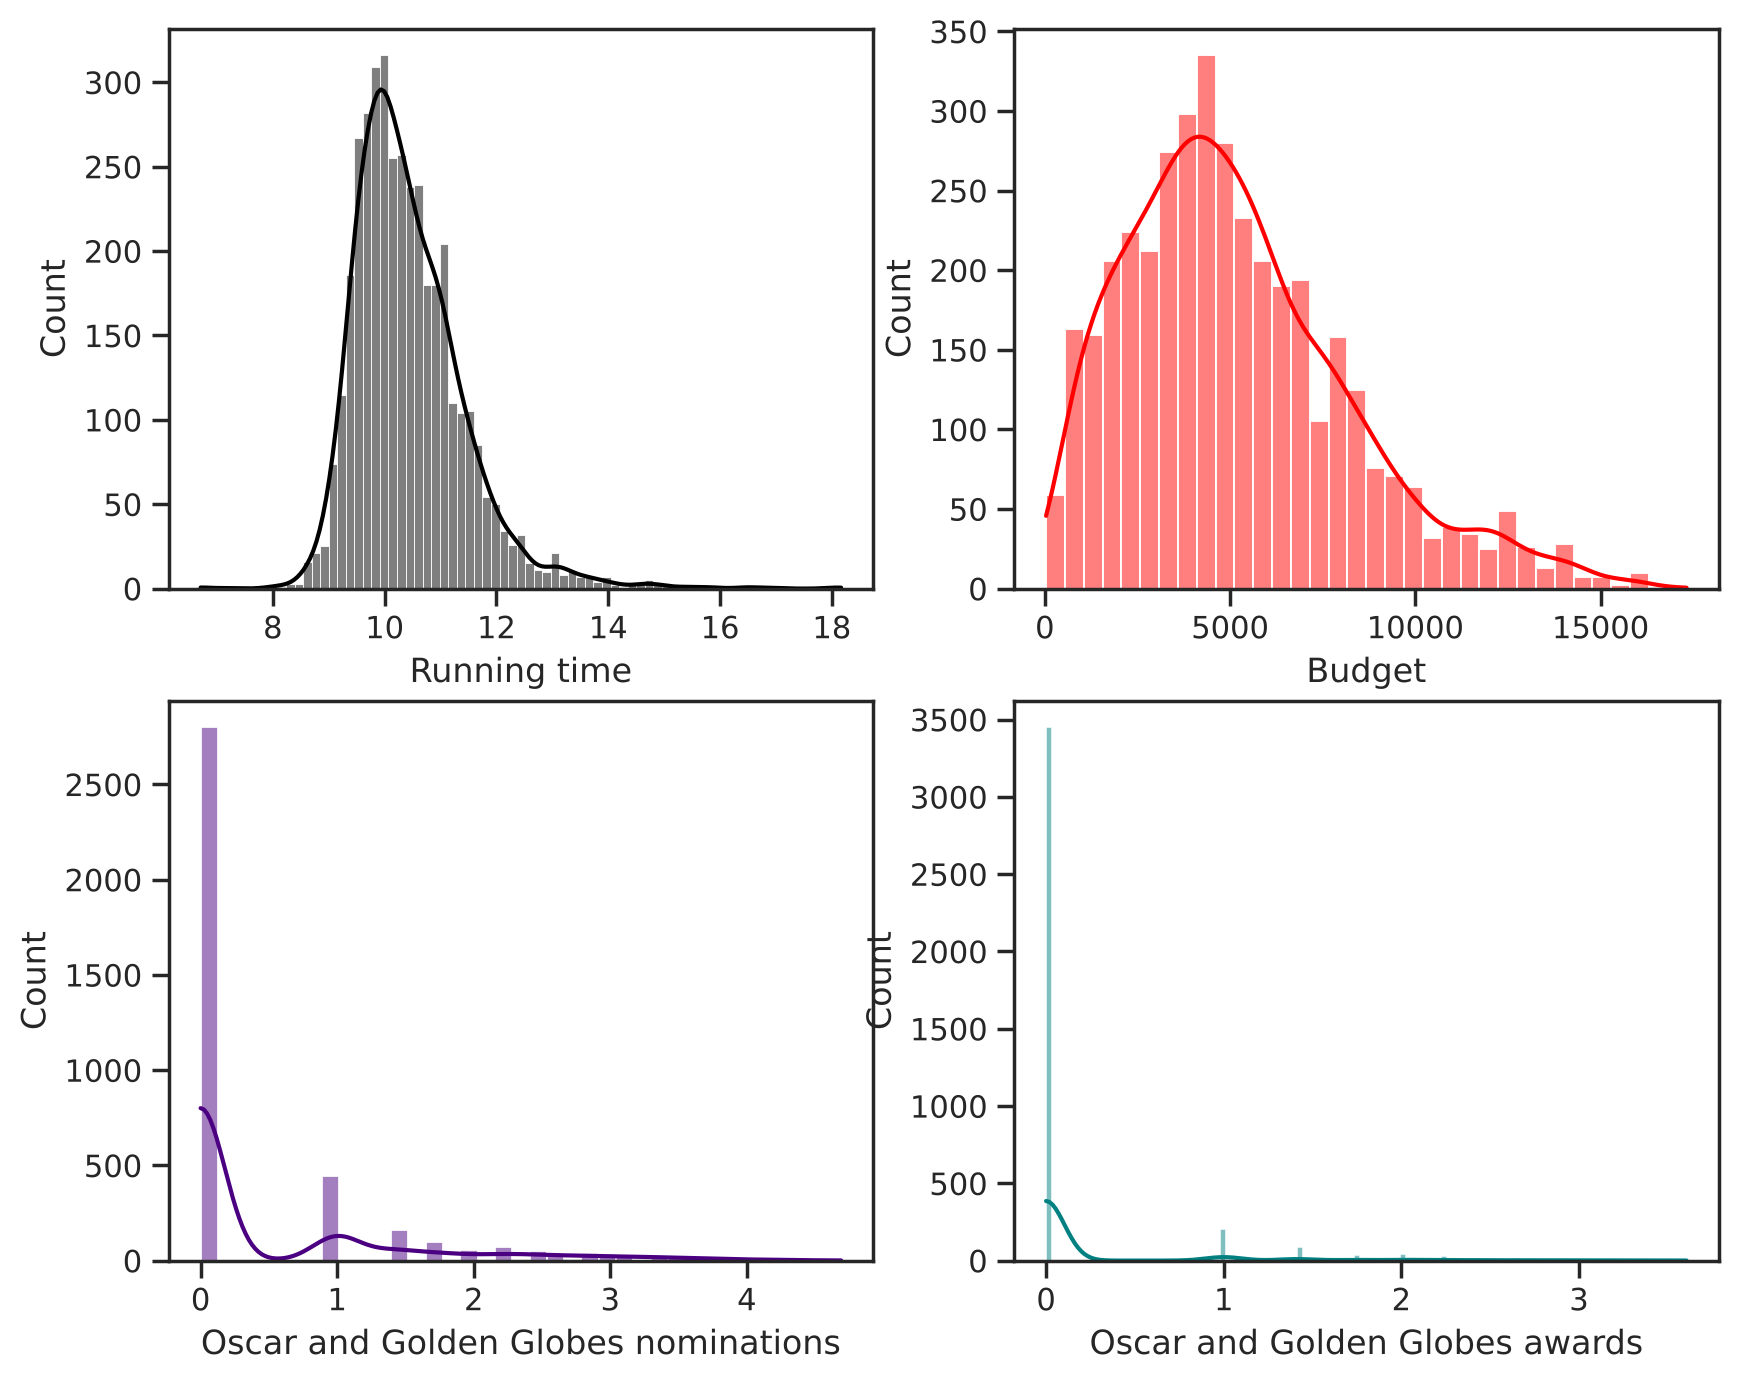

In [27]:
sns.set(style="ticks")
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
sns.histplot(data=df, x="Running time", kde=True, ax=axs[0, 0], color='black')
sns.histplot(data=df, x="Budget", kde=True, ax=axs[0, 1], color='red')
sns.histplot(data=df, x="Oscar and Golden Globes nominations", kde=True, ax=axs[1, 0], color='indigo')
sns.histplot(data=df, x="Oscar and Golden Globes awards", kde=True, ax=axs[1, 1], color='teal')
plt.show()

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [29]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
smote = SMOTE(random_state=0)
X_train, y_train = smote.fit_resample(X_train, y_train)

/tmp/ipykernel_325/862843918.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=y_train, palette="mako")


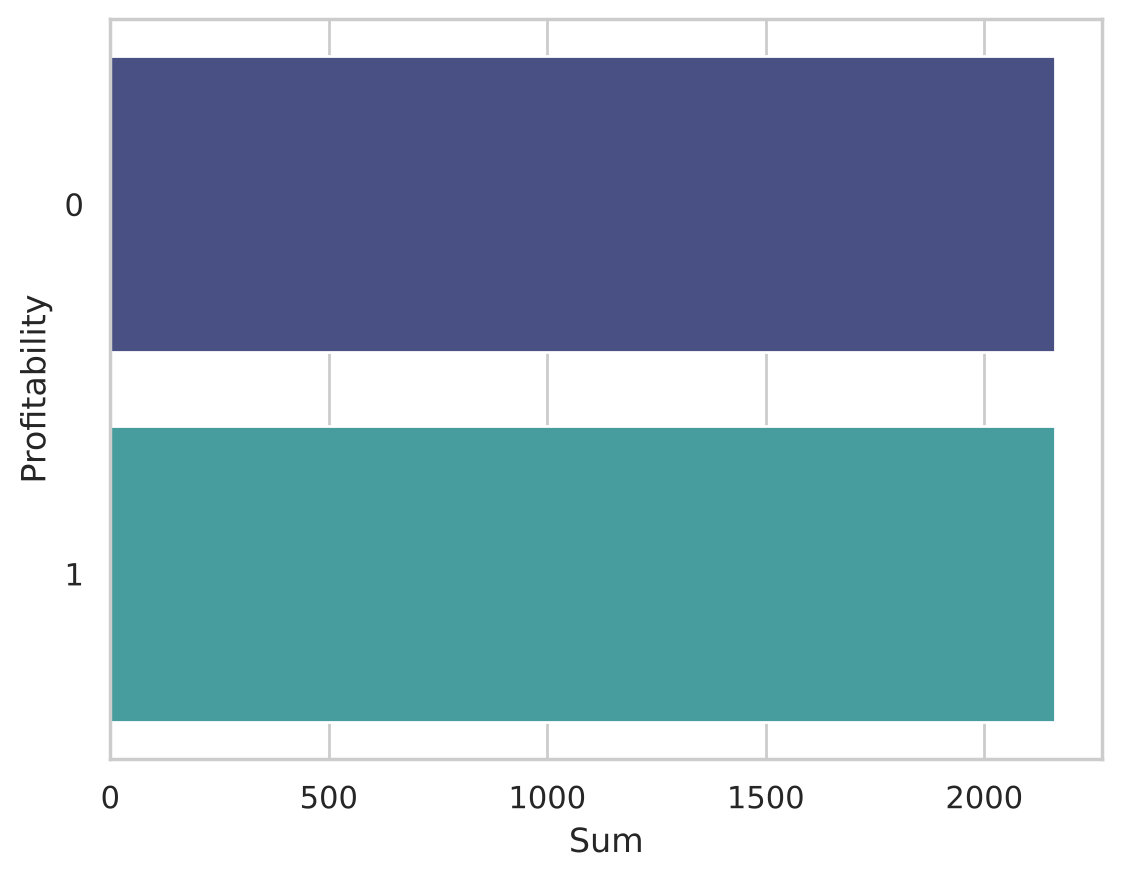

In [31]:
sns.set_theme(style="whitegrid")
sns.countplot(y=y_train, palette="mako")
plt.ylabel('Profitability')
plt.xlabel('Sum')
plt.show()

In [32]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=0)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [33]:
from sklearn.metrics import classification_report, accuracy_score

y_pred_dt = dt_model.predict(X_test)
print(classification_report(y_test, y_pred_dt))
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Accuracy: {round(accuracy_dt * 100, 2)}%")

              precision    recall  f1-score   support

           0       0.51      0.54      0.52       281
           1       0.81      0.79      0.80       696

    accuracy                           0.72       977
   macro avg       0.66      0.66      0.66       977
weighted avg       0.72      0.72      0.72       977

Accuracy: 71.75%


In [34]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=0)
lr_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [35]:
y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test, y_pred_lr))
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy: {round(accuracy_lr * 100, 2)}%")

              precision    recall  f1-score   support

           0       0.55      0.78      0.64       281
           1       0.89      0.74      0.81       696

    accuracy                           0.75       977
   macro avg       0.72      0.76      0.73       977
weighted avg       0.79      0.75      0.76       977

Accuracy: 75.23%


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=0)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [37]:
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf))
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy: {round(accuracy_rf * 100, 2)}%")

              precision    recall  f1-score   support

           0       0.58      0.66      0.62       281
           1       0.85      0.81      0.83       696

    accuracy                           0.76       977
   macro avg       0.72      0.73      0.72       977
weighted avg       0.77      0.76      0.77       977

Accuracy: 76.36%


In [38]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Logistic Regression', 'Random Forest'],
    'Accuracy (%)': [accuracy_dt * 100, accuracy_lr * 100, accuracy_rf * 100]
})
print(results)

                 Model  Accuracy (%)
0        Decision Tree     71.750256
1  Logistic Regression     75.230297
2        Random Forest     76.356192


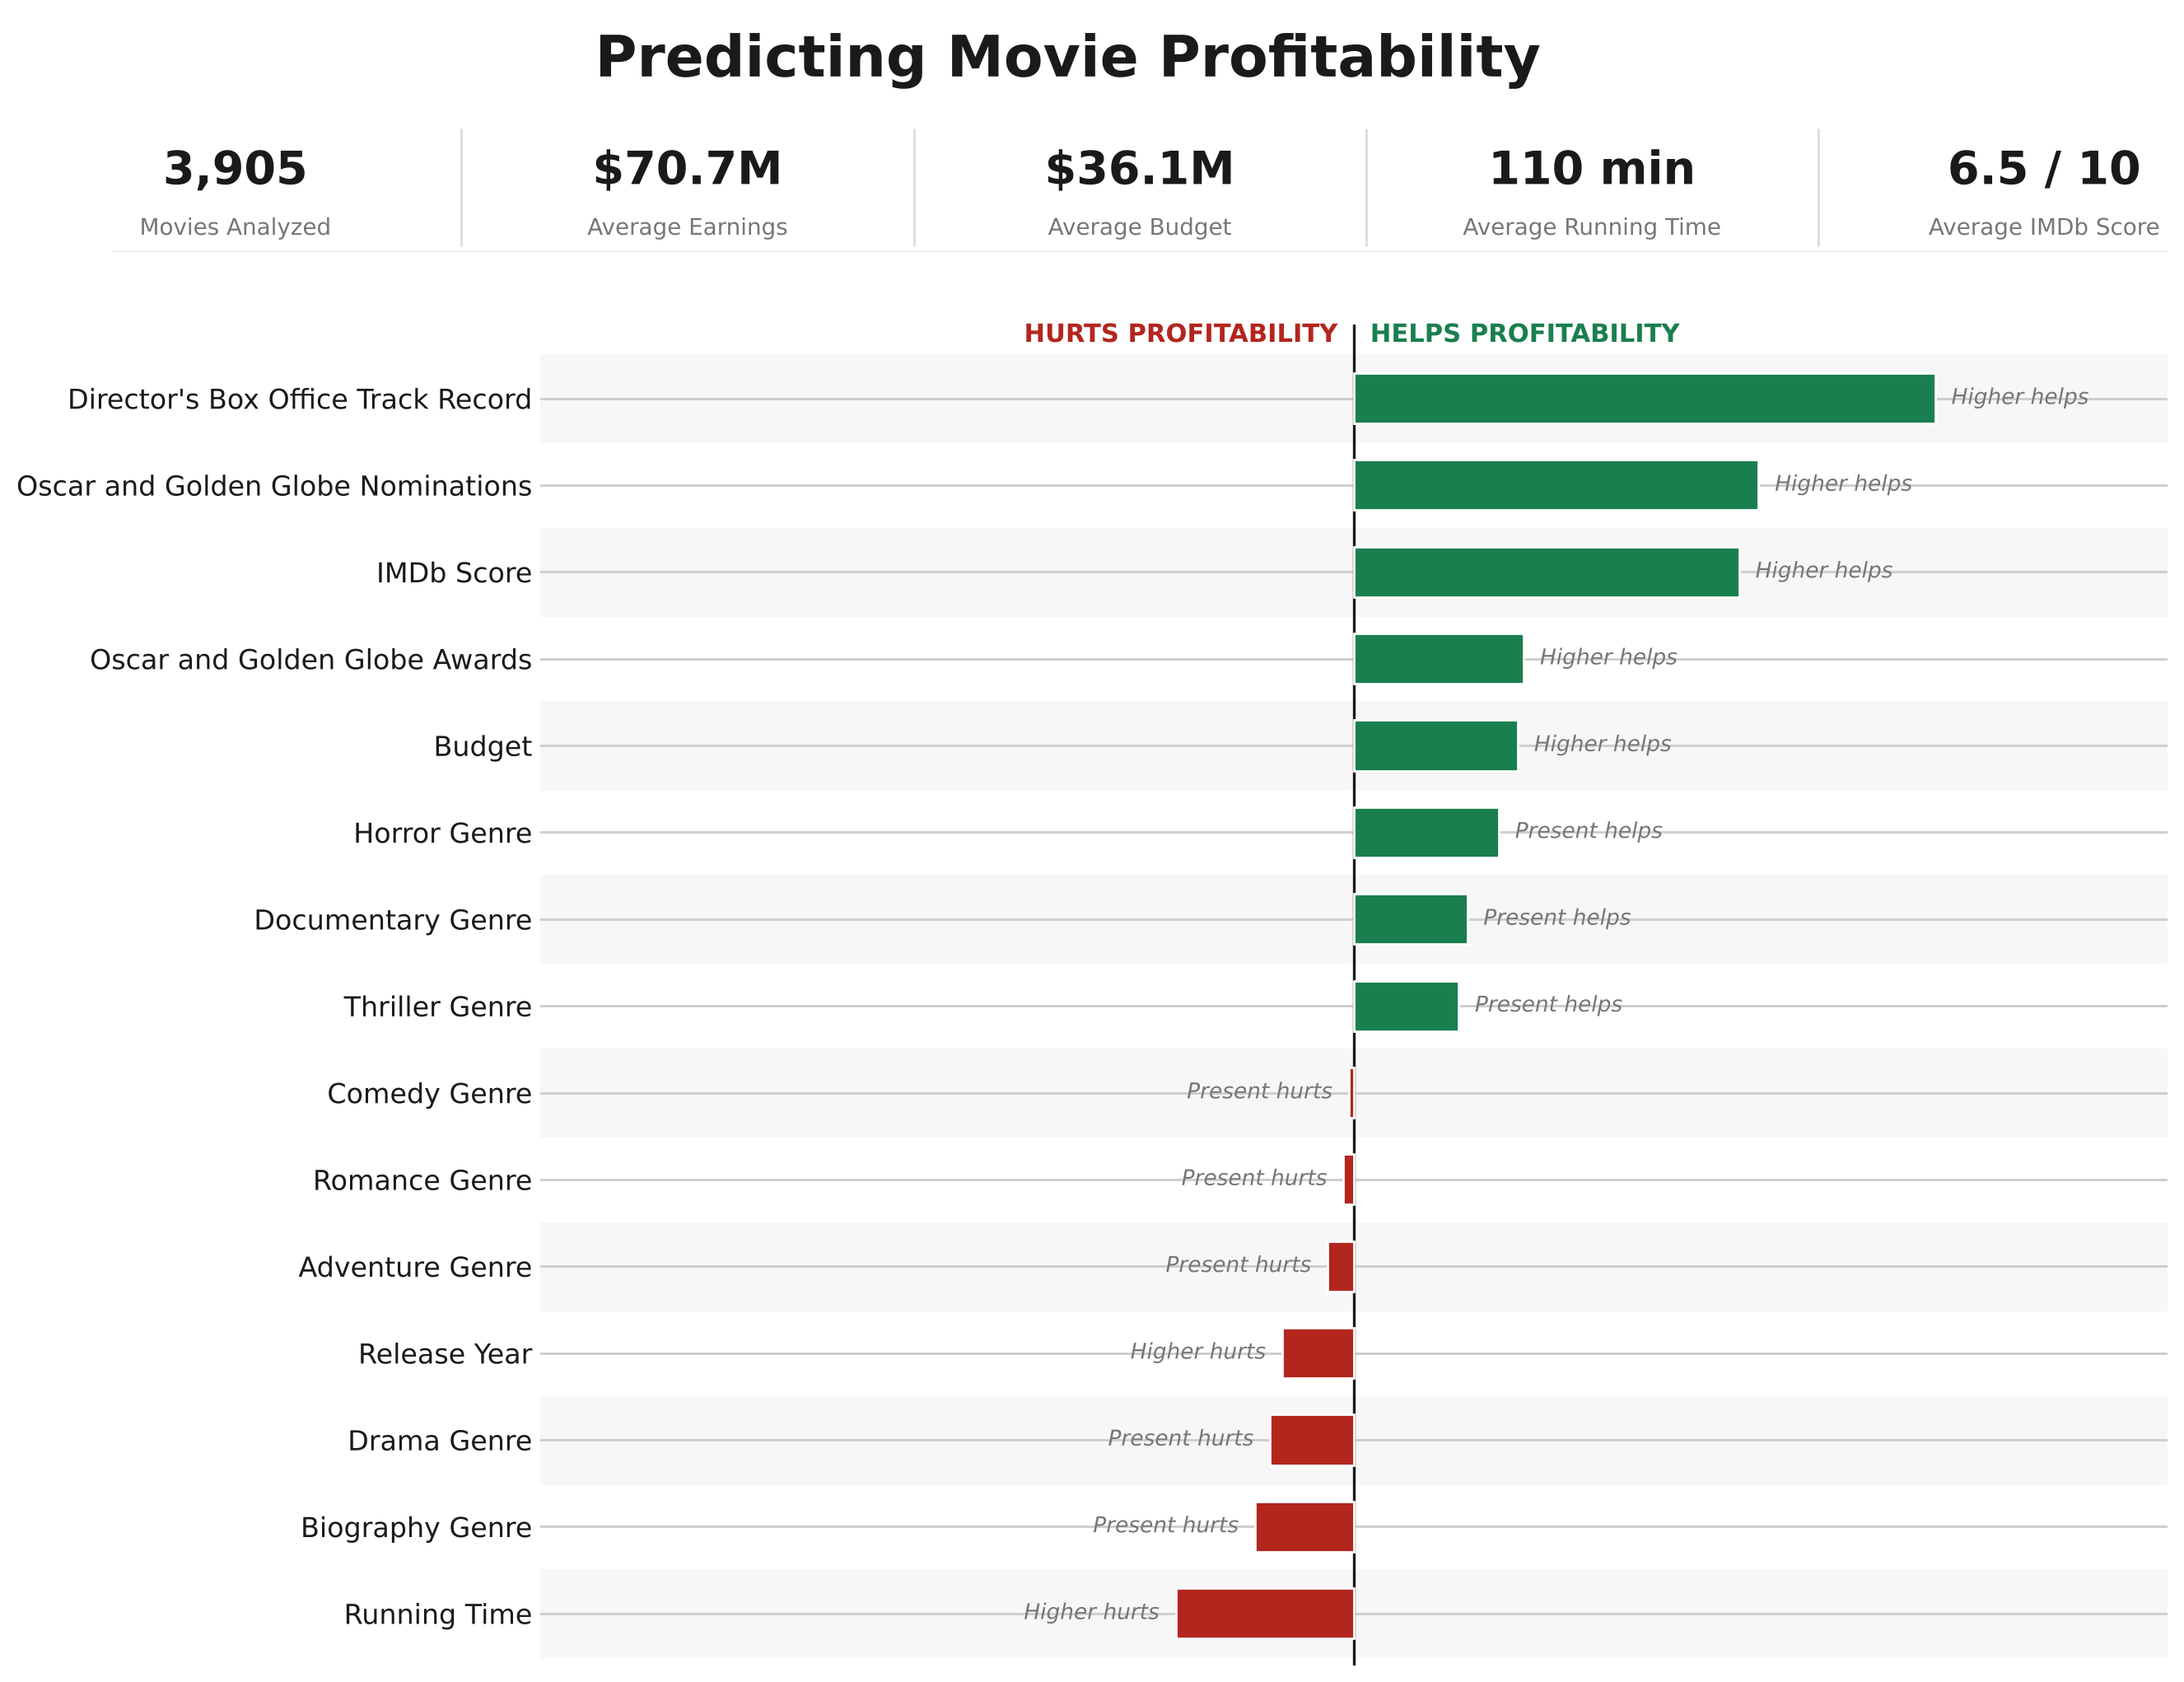

In [39]:
keep_mask = ~X.columns.str.startswith('Director_')
lr_all = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr_model.coef_[0]})
lr_all = lr_all[keep_mask].reset_index(drop=True)

continuous_features = {
    'Running time': 'Running Time',
    'Budget': 'Budget',
    'Director Box Office %': "Director's Box Office Track Record",
    'Oscar and Golden Globes nominations': 'Oscar and Golden Globe Nominations',
    'Oscar and Golden Globes awards': 'Oscar and Golden Globe Awards',
    'Release year': 'Release Year',
    'IMDb score': 'IMDb Score',
}


def clean_label(f):
  if f in continuous_features:
    return continuous_features[f]
  if f.startswith('Genre_'):
    return f.replace('Genre_', '') + ' Genre'
  return f


def direction_tag(f, coef):
  if f in continuous_features:
    return 'Higher helps' if coef > 0 else 'Higher hurts'
  return 'Present helps' if coef > 0 else 'Present hurts'


lr_all['Label'] = lr_all['Feature'].apply(clean_label)
lr_all['Tag'] = lr_all.apply(
    lambda r: direction_tag(r['Feature'], r['Coefficient']), axis=1
)

n_per_side = 8
top_pos = (
    lr_all[lr_all['Coefficient'] > 0]
    .sort_values('Coefficient', ascending=False)
    .head(n_per_side)
)
top_neg = (
    lr_all[lr_all['Coefficient'] < 0]
    .sort_values('Coefficient')
    .head(n_per_side)
)
plot_df = pd.concat(
    [top_neg.sort_values('Coefficient'), top_pos.sort_values('Coefficient')]
).reset_index(drop=True)

BG = '#ffffff'
TEXT_DARK = '#1a1a1a'
TEXT_GRAY = '#767676'
GREEN = '#1a7f4e'
RED = '#b3261e'
LINE = '#dcdcdc'

plt.rcParams['font.family'] = 'DejaVu Sans'

stats = [
    (f'{df.shape[0]:,}', 'Movies Analyzed'),
    ('$70.7M', 'Average Earnings'),
    ('$36.1M', 'Average Budget'),
    ('110 min', 'Average Running Time'),
    ('6.5 / 10', 'Average IMDb Score'),
]

fig = plt.figure(figsize=(13, 11), facecolor=BG)

# Header GridSpec
gs_top = fig.add_gridspec(
    2,
    1,
    height_ratios=[0.35, 0.5],
    hspace=0.15,
    top=0.95,
    bottom=0.82,
    left=0.02,
    right=0.98,
)

# Plot GridSpec
gs_bottom = fig.add_gridspec(
    1, 1, top=0.78, bottom=0.04, left=0.22, right=0.98
)

# Title section - x=0.465 counteracts bbox_inches='tight' rightward shift
ax_title = fig.add_subplot(gs_top[0])
ax_title.axis('off')
ax_title.set_xlim(0, 1)
ax_title.set_ylim(0, 1)
ax_title.text(
    0.465,
    0.5,
    'Predicting Movie Profitability',
    ha='center',
    va='center',
    fontsize=25,
    fontweight='bold',
    color=TEXT_DARK,
)

# Key statistics banner
ax_stats = fig.add_subplot(gs_top[1])
ax_stats.axis('off')
ax_stats.set_xlim(0, 1)
ax_stats.set_ylim(0, 1)

n = len(stats)
positions = np.linspace(0.06, 0.94, n)
for (num, label), x in zip(stats, positions):
  ax_stats.text(
      x,
      0.62,
      num,
      ha='center',
      va='center',
      fontsize=20,
      fontweight='bold',
      color=TEXT_DARK,
  )
  ax_stats.text(
      x, 0.18, label, ha='center', va='center', fontsize=10, color=TEXT_GRAY
  )
for x in positions[1:]:
  ax_stats.axvline(
      x - (positions[1] - positions[0]) / 2,
      ymin=0.05,
      ymax=0.95,
      color=LINE,
      linewidth=1,
  )
ax_stats.axhline(0, color=LINE, linewidth=1)

# Main horizontal bar plot
ax = fig.add_subplot(gs_bottom[0])
ax.set_facecolor(BG)

for i in range(len(plot_df)):
  if i % 2 == 0:
    ax.axhspan(i - 0.5, i + 0.5, color='#f7f7f7', zorder=0)

colors = [GREEN if c > 0 else RED for c in plot_df['Coefficient']]
bars = ax.barh(
    plot_df['Label'],
    plot_df['Coefficient'],
    color=colors,
    height=0.58,
    zorder=3,
)

ax.axvline(0, color=TEXT_DARK, linewidth=1.2, zorder=2)

for spine in ax.spines.values():
  spine.set_visible(False)

plt.setp(ax.get_yticklabels(), fontsize=12, color=TEXT_DARK)
ax.tick_params(axis='y', length=0)
ax.set_xticks([])
ax.set_ylim(-0.6, len(plot_df) - 0.15)

xmax = plot_df['Coefficient'].abs().max() * 1.4
ax.set_xlim(-xmax, xmax)

for bar, coef, tag in zip(bars, plot_df['Coefficient'], plot_df['Tag']):
  width = bar.get_width()
  ypos = bar.get_y() + bar.get_height() / 2
  if width >= 0:
    ax.text(
        width + xmax * 0.02,
        ypos,
        tag,
        va='center',
        ha='left',
        fontsize=9.5,
        color=TEXT_GRAY,
        style='italic',
    )
  else:
    ax.text(
        width - xmax * 0.02,
        ypos,
        tag,
        va='center',
        ha='right',
        fontsize=9.5,
        color=TEXT_GRAY,
        style='italic',
    )

ax.text(
    xmax * 0.02,
    len(plot_df) - 0.35,
    'HELPS PROFITABILITY',
    fontsize=11,
    fontweight='bold',
    color=GREEN,
    ha='left',
)
ax.text(
    -xmax * 0.02,
    len(plot_df) - 0.35,
    'HURTS PROFITABILITY',
    fontsize=11,
    fontweight='bold',
    color=RED,
    ha='right',
)

plt.savefig(
    'movie_profitability_feature_importance.png',
    dpi=200,
    facecolor=BG,
    bbox_inches='tight',
)
plt.show()

In [40]:
# ============================================================
#                    TEST YOUR OWN MOVIE
# ============================================================
my_movie = {
    'Director': 'Name',
    'Running time': 110,#minutes
    'Genre': 'Action',
    'Budget': 36100000,#dollars
    'Director Box Office %': 0,          # % of director's other films that were profitable
    'Oscar and Golden Globes nominations': 0,
    'Oscar and Golden Globes awards': 0,
    'Release year': 2016,
    'IMDb score': 6.5
}

# ------------------------------------------------------------
#           (below this line: pre-processing, don't edit)
# ------------------------------------------------------------

new_df = pd.DataFrame([my_movie])
new_df = pd.get_dummies(new_df, columns=['Genre'])

if my_movie['Director'] in top10_directors:
    director_label = my_movie['Director']
else:
    match = director_counts.get(my_movie['Director'])
    director_label = f'{match} film(s) directed' if match is not None else '1 film(s) directed'
new_df['Director'] = director_label
new_df = pd.get_dummies(new_df, columns=['Director'])

new_df = new_df.reindex(columns=X.columns, fill_value=0)

for col in skewed_cols:
    new_df[col] = np.sqrt(new_df[col])

new_scaled = scaler.transform(new_df)

# ------------------------------------------------------------
#                        RESULTS
# ------------------------------------------------------------
print("=" * 40)
print(f"  PREDICTION FOR: {my_movie['Director']}'s film")
print("=" * 40)
for name, model in [('Decision Tree', dt_model), ('Logistic Regression', lr_model), ('Random Forest', rf_model)]:
    pred = model.predict(new_scaled)[0]
    label = 'PROFITABLE' if pred == 1 else 'NOT PROFITABLE'
    print(f"  {name:<22} -> {label}")
print("=" * 40)

  PREDICTION FOR: Name's film
  Decision Tree          -> NOT PROFITABLE
  Logistic Regression    -> NOT PROFITABLE
  Random Forest          -> NOT PROFITABLE


In [41]:
# Which features mattered most to each model?

# Random Forest: importance = how much each feature reduced impurity across all trees
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Logistic Regression: coefficient size/direction = how much each feature pushes the prediction
# toward Profitable (positive) or Not Profitable (negative)
lr_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("Random Forest - Top 10 most important features:")
print(rf_importance.head(10).to_string(index=False))

print("\nLogistic Regression - Top 10 most influential features:")
print(lr_importance.head(10).to_string(index=False))

Random Forest - Top 10 most important features:
                            Feature  Importance
              Director Box Office %    0.294379
                             Budget    0.128165
                         IMDb score    0.124101
                       Release year    0.103952
                       Running time    0.101748
Oscar and Golden Globes nominations    0.073038
     Oscar and Golden Globes awards    0.024234
                        Genre_Drama    0.013748
                       Genre_Comedy    0.013563
        Director_2 film(s) directed    0.010497

Logistic Regression - Top 10 most influential features:
                            Feature  Coefficient
              Director Box Office %     4.259248
Oscar and Golden Globes nominations     2.965950
                         IMDb score     2.823112
       Director_11 film(s) directed    -1.379035
                       Running time    -1.306409
               Director_Woody Allen    -1.303109
     Oscar and Golden Gl